**1. Imports**

In [34]:
from eeg_framework.datasets      import *
from eeg_framework.preprocessing import *
from eeg_framework.plotting      import *
from eeg_framework.features      import *
from eeg_framework.models        import *
from eeg_framework.evaluate      import *

**2. Load Data**


In [35]:
root_dir = "data//OpenBMI MI//"
subjects = [2]
filter_param = {"l_freq": 8.0, "h_freq": 30.0, "notch_freq": 60.0}

epochs_train = load_openbmi_mi(root_dir=root_dir, split="train", subjects=subjects, concatenate=True, **filter_param)
epochs_test  = load_openbmi_mi(root_dir=root_dir, split="test",  subjects=subjects, concatenate=True, **filter_param)

Adding metadata with 3 columns
[OpenBMIMI] subject=1 session=1 split='train' | 100 epochs | 62 ch | 1000 Hz
Adding metadata with 3 columns
[OpenBMIMI] subject=1 session=2 split='train' | 100 epochs | 62 ch | 1000 Hz
Adding metadata with 3 columns
[OpenBMIMI] subject=1 session=1 split='test' | 100 epochs | 62 ch | 1000 Hz
Adding metadata with 3 columns
[OpenBMIMI] subject=1 session=2 split='test' | 100 epochs | 62 ch | 1000 Hz


In [36]:
epochs_train

<EpochsArray | 200 events (all good), -0.5 – 4 s (baseline off), ~425.9 MiB, data loaded, with metadata,
 'right': 100
 'left': 100>

**3. Preprocessing**

In [37]:
pipe_preprocessing = PreprocessingPipeline([
    ('crop', Crop(tmin=0.5, tmax=3.5)),
    ('rs',  Resample(100.0)),
    # ('ica', ICA(random_state=4))    
    # ...
])

epochs_train_f = pipe_preprocessing.fit_transform(epochs_train)
epochs_test_f  = pipe_preprocessing.transform(epochs_test)

[Pipeline] fit_transform → crop
[Pipeline] fit_transform → rs
[Pipeline] applying → crop
[Pipeline] applying → rs


**4. Plotting**

Topomap - Topographic Map

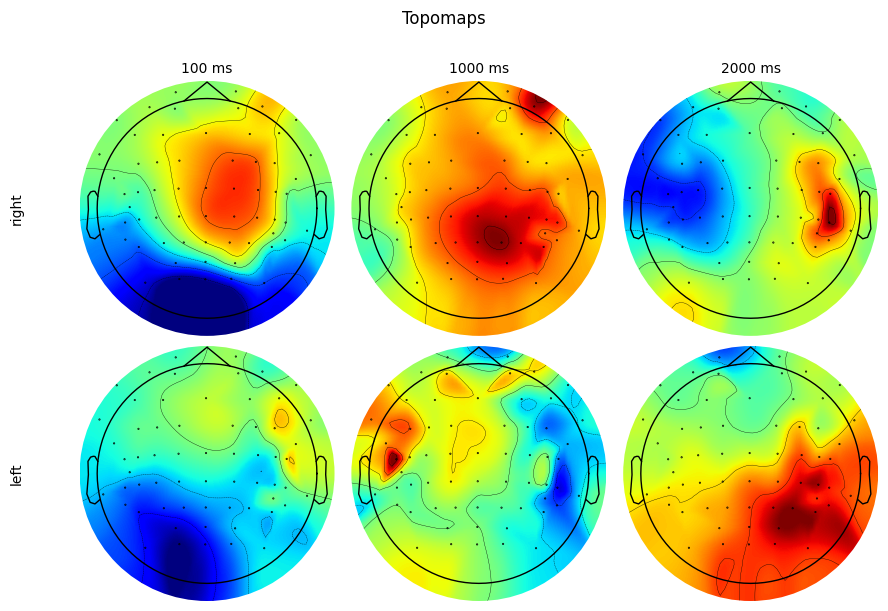

In [38]:
times = [0.1, 1.0, 2.0] # Time [s]
# Before processing
plot_topomap(epochs_train, times = times)
# After processing
#plot_topomap(epochs_train_f, times = times)

PSD - Power Spectral Density

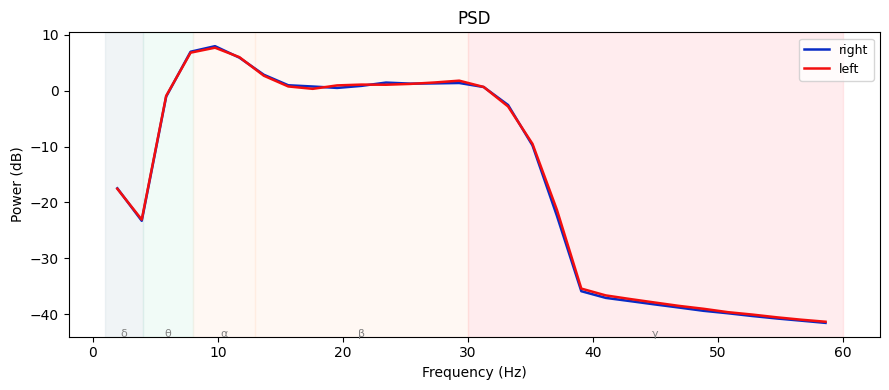

In [39]:
# Before preprocessing
plot_psd(epochs_train)
# After preprocessing
# plot_psd(epochs_train_f)

TFR - Time-frequency

In [40]:
# Before preprocessing
# plot_tfr(epochs_train)
# After preprocessing
#plot_tfr(epochs_train_f)

**5. Features**

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle

pipe_feature = FeaturePipeline([
    ('CSP', CSP()),
    # ...
])

X_train, y_train = pipe_feature.fit_transform(epochs_train_f)
X_test, y_test = pipe_feature.transform(epochs_test_f)


X_train, y_train = shuffle(X_train, y_train)
X_test, y_test = shuffle(X_test, y_test)

[FeaturePipeline] fitting → CSP
Computing rank from data with rank=None
    Using tolerance 1.4e+02 (2.2e-16 eps * 62 dim * 1e+16  max singular value)
    Estimated rank (data): 62
    data: rank 62 computed from 62 data channels with 0 projectors
Reducing data rank from 62 -> 62
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 1.4e+02 (2.2e-16 eps * 62 dim * 1e+16  max singular value)
    Estimated rank (data): 62
    data: rank 62 computed from 62 data channels with 0 projectors
Reducing data rank from 62 -> 62
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
[CSP] fitted OVR for 2 classes | total features: 12
[FeaturePipeline] extracting → CSP
[FeaturePipeline] extracting → CSP


**6. Classification**

In [42]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# EEGNet Example
clf_model = LDA()

clf_model.fit(X_train, y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


**7. Evaluation**

─────────────────────────────────────────────
  Accuracy        : 0.6950
  F1 (macro)      : 0.6928
  F1 (weighted)   : 0.6928
  Recall (macro)  : 0.6950
  Cohen's Kappa   : 0.3900
─────────────────────────────────────────────
  Class           Accuracy        F1    Recall
─────────────────────────────────────────────
  0                 0.7800    0.7189    0.7800
  1                 0.6100    0.6667    0.6100
─────────────────────────────────────────────


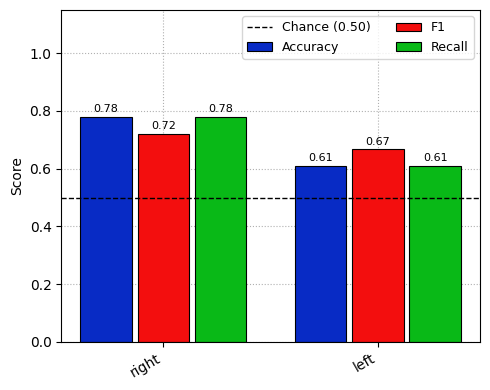

In [43]:

class_names = list(epochs_train.event_id.keys())
y_pred = clf_model.predict(X_test)

# Metrics
summary(y_test, y_pred)

# Plots
fig = plot_metrics_bar(y_test, y_pred, class_names=class_names)
# ....

**8. t-SNE**

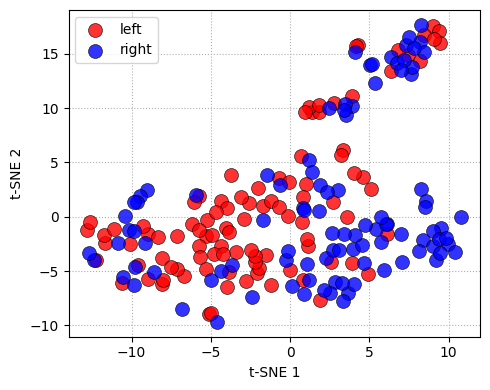

In [44]:
plot_tsne(X_train, y_train, class_names={0: "left", 1: "right"})